**Name:** Ishan Kulkarni
**Branch:** CSSE-B
**Roll no.:** 32

# PAS Home Assignment 4

## Aim
A university intends to predict
students' final examination performance using attributes such as attendance,
study hours, assignment scores, and internal assessment marks. Using Python and
suitable machine learning libraries, preprocess the dataset, perform
exploratory data analysis, identify relationships among variables through
correlation analysis, develop a simple linear regression model for predicting
final examination marks, evaluate the model using appropriate regression
performance metrics, visualize the prediction results, interpret the findings,
and present the complete analysis through a concise technical report.

> I recommend to check the notebook from Github to get the latest version: [Github](https://github.com/ishanKulkarni13/PAS_college/blob/main/ha-4/ha-4.ipynb)

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Loading the Dataset

In [2]:
df = pd.read_csv('PAS-HA_4-Probability_Statistics_Datasets.csv')
df.head()

,Student_ID,Attendance_%,Study_Hours,Assignment_Marks,Internal_Marks,Final_Exam_Marks
0,1,95,1.8,87,70,73
1,2,69,2.0,46,46,54
2,3,57,1.2,53,64,60
3,4,93,1.2,52,88,69
4,5,83,5.1,91,35,65


## Understanding the Dataset

In [3]:
df.shape

(100, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student_ID        100 non-null    int64  
 1   Attendance_%      100 non-null    int64  
 2   Study_Hours       100 non-null    float64
 3   Assignment_Marks  100 non-null    int64  
 4   Internal_Marks    100 non-null    int64  
 5   Final_Exam_Marks  100 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 4.8 KB


## Preprocessing

In [5]:
df.isnull().sum()

Student_ID          0
Attendance_%        0
Study_Hours         0
Assignment_Marks    0
Internal_Marks      0
Final_Exam_Marks    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

No missing values and no duplicate rows, and all the columns are already numbers, so no encoding is needed.

`Student_ID` is only a label for the student, it has no meaning for predicting marks, so it is dropped. Scaling is also not needed for simple linear regression, and keeping the original units makes the slope easier to read.

In [7]:
df = df.drop(columns='Student_ID')
df.describe().round(2)

,Attendance_%,Study_Hours,Assignment_Marks,Internal_Marks,Final_Exam_Marks
count,100.00,100.00,100.00,100.00,100.00
mean,77.38,4.27,74.34,66.87,71.14
std,13.46,2.15,16.83,18.71,10.57
min,55.00,1.10,42.00,35.00,49.00
25%,65.00,2.28,58.75,49.00,63.00
50%,78.50,4.05,76.00,66.50,72.00
75%,89.00,6.02,88.50,81.00,78.00
max,100.00,7.80,99.00,100.00,96.00


## Exploratory Data Analysis

Distribution of each variable first.

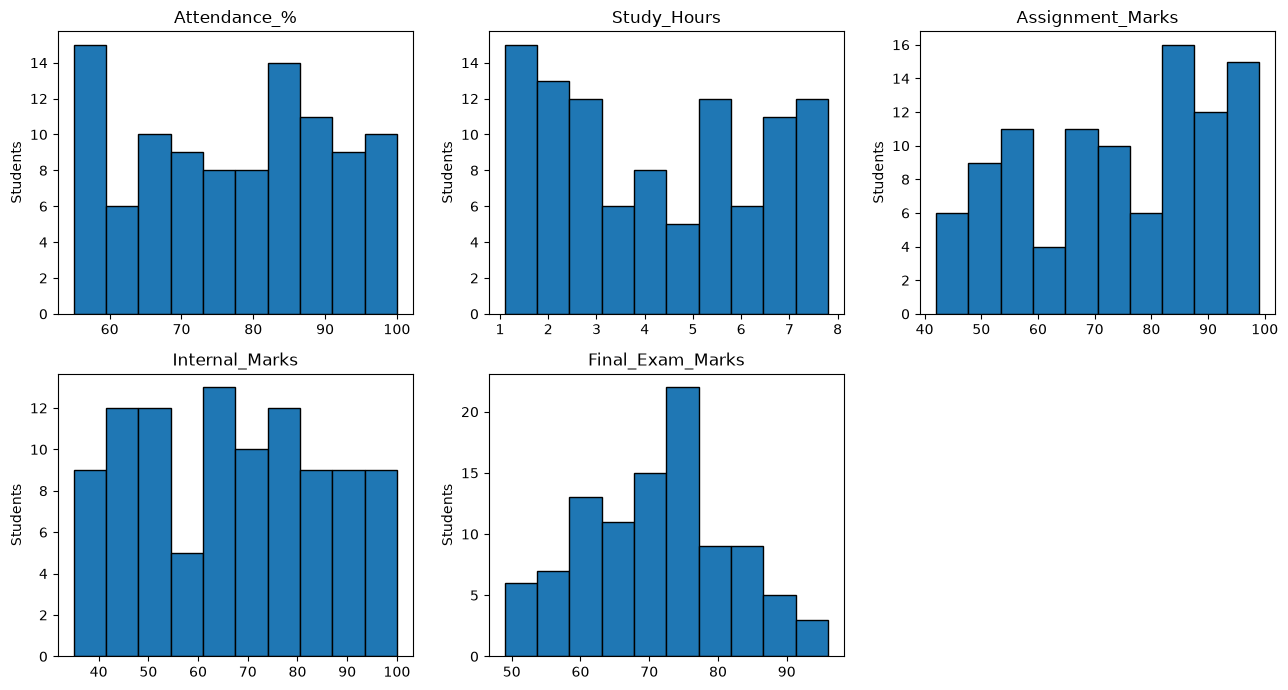

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, df.columns):
    ax.hist(df[col], bins=10, edgecolor='black')
    ax.set_title(col)
    ax.set_ylabel('Students')
axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

Final_Exam_Marks looks roughly bell shaped, the others are spread out without any big outliers.

Now each factor against the final exam marks:

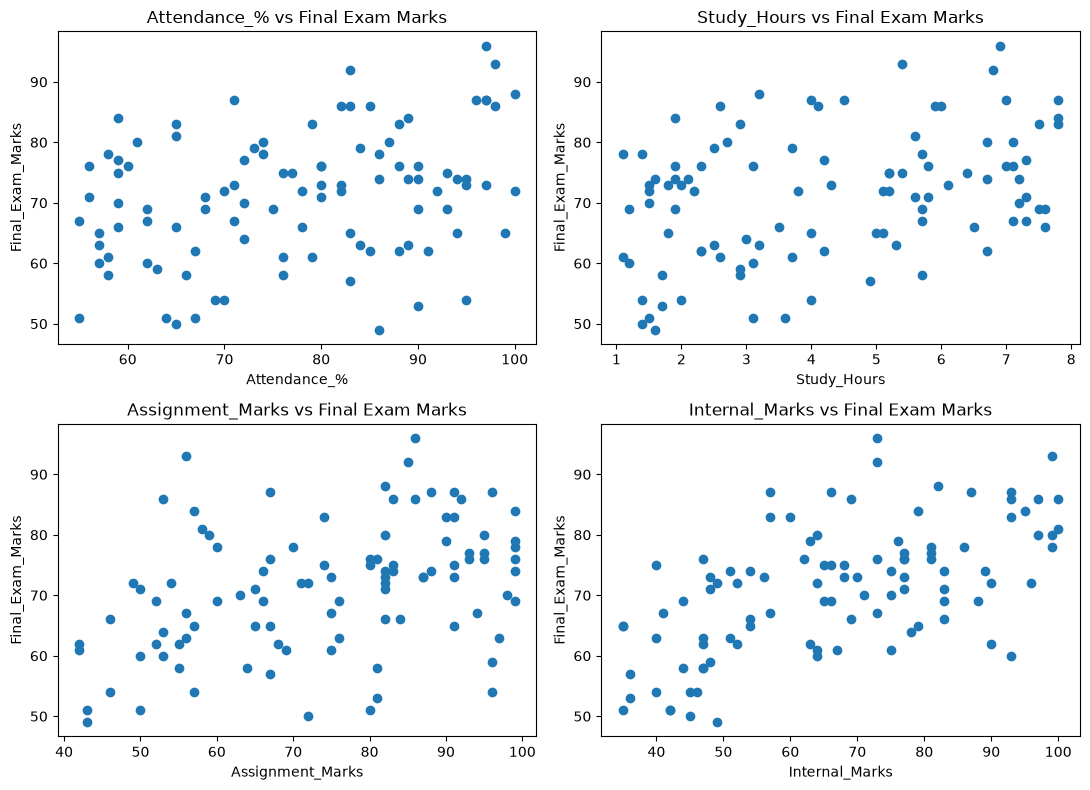

In [9]:
predictors = ['Attendance_%', 'Study_Hours', 'Assignment_Marks', 'Internal_Marks']

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, predictors):
    ax.scatter(df[col], df['Final_Exam_Marks'])
    ax.set_xlabel(col)
    ax.set_ylabel('Final_Exam_Marks')
    ax.set_title(col + ' vs Final Exam Marks')
plt.tight_layout()
plt.show()

## Correlation Analysis

Pearson correlation coefficient r tells how strong the straight line relationship between two variables is (−1 to +1). Interpreting the size as in Unit I: 0.3 to 0.69 is moderate, below 0.3 is weak.

In [10]:
corr = df.corr()
corr.round(3)

,Attendance_%,Study_Hours,Assignment_Marks,Internal_Marks,Final_Exam_Marks
Attendance_%,1.000,-0.111,0.051,0.095,0.317
Study_Hours,-0.111,1.000,0.044,-0.117,0.368
Assignment_Marks,0.051,0.044,1.000,-0.043,0.394
Internal_Marks,0.095,-0.117,-0.043,1.000,0.599
Final_Exam_Marks,0.317,0.368,0.394,0.599,1.000


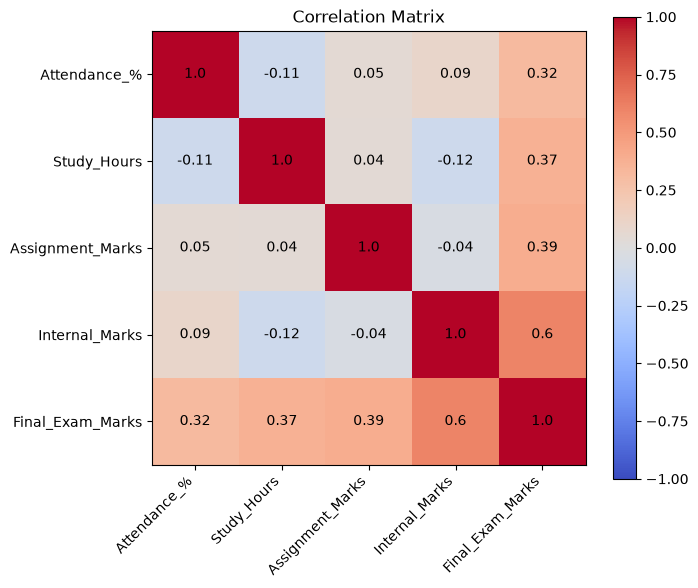

In [11]:
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center')
plt.colorbar()
plt.title('Correlation Matrix')
plt.show()

In [12]:
for col in predictors:
    r, p = stats.pearsonr(df[col], df['Final_Exam_Marks'])
    print(f'{col:18s} r = {r:.3f}   p-value = {p:.2e}')

Attendance_%       r = 0.317   p-value = 1.32e-03
Study_Hours        r = 0.368   p-value = 1.69e-04
Assignment_Marks   r = 0.394   p-value = 4.91e-05
Internal_Marks     r = 0.599   p-value = 4.63e-11


All four are positively correlated with the final marks and all the correlations are statistically significant (p < 0.05). **Internal_Marks** has the highest correlation (0.60, moderate) and the others are weaker (0.32 to 0.39). The factors are also hardly correlated with each other (all well below 0.2), so there is no problem of two predictors carrying the same information.

Since the aim is a *simple* linear regression (one predictor), Internal_Marks is chosen as the predictor.

## Train-Test Split

80% of the students are used to train the model and the remaining 20% are kept aside to test it on data that it has not seen.

In [13]:
X = df[['Internal_Marks']]
y = df['Final_Exam_Marks']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training students:', len(X_train))
print('Testing students :', len(X_test))

Training students: 80
Testing students : 20


## Simple Linear Regression

The model is  Final_Exam_Marks = b0 + b1 × Internal_Marks. The line is found by least squares, which minimises the sum of the squared errors: b1 = Cov(X, Y) / Var(X) and b0 = ȳ − b1 x̄.

In [14]:
model = LinearRegression()
model.fit(X_train, y_train)

b0 = model.intercept_
b1 = model.coef_[0]
print('Intercept (b0):', round(b0, 4))
print('Slope (b1)    :', round(b1, 4))
print(f'Final_Exam_Marks = {b0:.2f} + {b1:.3f} x Internal_Marks')

Intercept (b0): 46.4212
Slope (b1)    : 0.3642
Final_Exam_Marks = 46.42 + 0.364 x Internal_Marks


Checking the formula by hand on the training data:

In [15]:
x_tr = X_train['Internal_Marks']
b1_hand = np.cov(x_tr, y_train)[0, 1] / np.var(x_tr, ddof=1)
b0_hand = y_train.mean() - b1_hand * x_tr.mean()
print('b1 by formula:', round(b1_hand, 4))
print('b0 by formula:', round(b0_hand, 4))

b1 by formula: 0.3642
b0 by formula: 46.4212


In [16]:
new_marks = pd.DataFrame({'Internal_Marks': [45, 65, 85]})
for m, pred in zip(new_marks['Internal_Marks'], model.predict(new_marks)):
    print('Internal marks', m, '-> predicted final marks', round(pred, 1))

Internal marks 45 -> predicted final marks 62.8
Internal marks 65 -> predicted final marks 70.1
Internal marks 85 -> predicted final marks 77.4


## Model Evaluation

In [17]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def get_metrics(actual, pred):
    mse = mean_squared_error(actual, pred)
    return {'MAE': mean_absolute_error(actual, pred),
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'R2': r2_score(actual, pred)}

results = pd.DataFrame({'Training': get_metrics(y_train, y_pred_train),
                        'Testing': get_metrics(y_test, y_pred_test)}).T
results.round(4)

,MAE,MSE,RMSE,R2
Training,6.8364,73.2528,8.5588,0.3795
Testing,6.5699,63.5697,7.9731,0.2068


- **MAE** - average size of the error in marks
- **MSE** - average of the squared errors (large mistakes are punished more)
- **RMSE** - square root of MSE, so it is back in marks
- **R²** - fraction of the variation in final marks that the model explains (1 is perfect, 0 is no better than always predicting the mean)

## Visualizing the Results

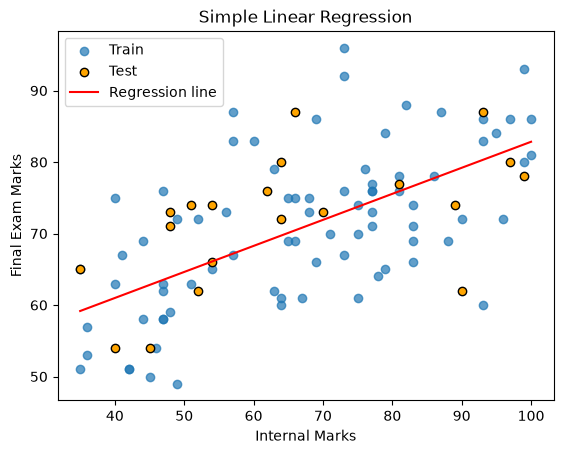

In [18]:
x_line = pd.DataFrame({'Internal_Marks': np.linspace(X['Internal_Marks'].min(), X['Internal_Marks'].max(), 50)})

plt.scatter(X_train, y_train, label='Train', alpha=0.7)
plt.scatter(X_test, y_test, color='orange', edgecolor='black', label='Test')
plt.plot(x_line['Internal_Marks'], model.predict(x_line), color='red', label='Regression line')
plt.xlabel('Internal Marks')
plt.ylabel('Final Exam Marks')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

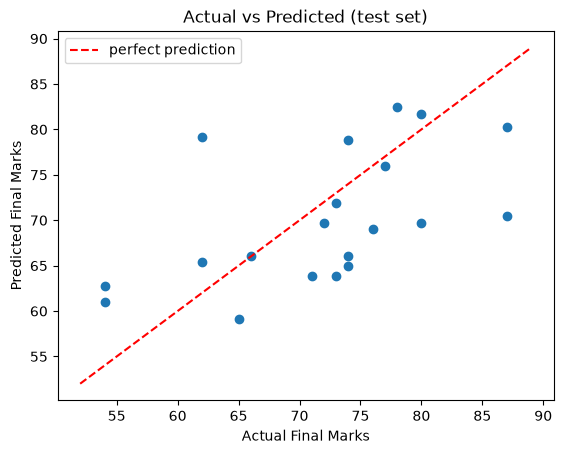

In [19]:
plt.scatter(y_test, y_pred_test)
low = min(y_test.min(), y_pred_test.min()) - 2
high = max(y_test.max(), y_pred_test.max()) + 2
plt.plot([low, high], [low, high], 'r--', label='perfect prediction')
plt.xlabel('Actual Final Marks')
plt.ylabel('Predicted Final Marks')
plt.title('Actual vs Predicted (test set)')
plt.legend()
plt.show()

In [20]:
comp = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred_test.round(1)})
comp['Error'] = (comp['Actual'] - comp['Predicted']).round(1)
comp.head(10)

,Actual,Predicted,Error
0,80,69.7,10.3
1,78,82.5,-4.5
2,54,61.0,-7.0
3,62,65.4,-3.4
4,73,63.9,9.1
5,80,81.8,-1.8
6,74,78.8,-4.8
7,87,70.5,16.5
8,72,69.7,2.3
9,73,71.9,1.1


## Checking the Residuals

Residual = actual - predicted. For linear regression to be reasonable, the residuals should have no pattern against the predicted values, have roughly equal spread, and be roughly normal.

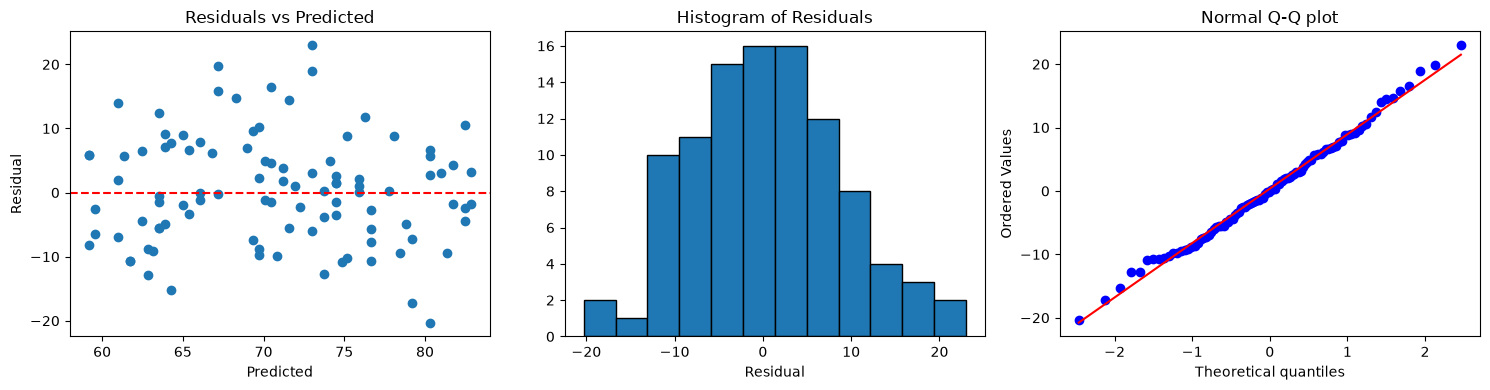

Mean of residuals: 0.3637
Shapiro-Wilk p-value: 0.8988


In [21]:
resid = y - model.predict(X)
fitted = model.predict(X)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(fitted, resid)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Predicted')

axes[1].hist(resid, bins=12, edgecolor='black')
axes[1].set_xlabel('Residual')
axes[1].set_title('Histogram of Residuals')

stats.probplot(resid, dist='norm', plot=axes[2])
axes[2].set_title('Normal Q-Q plot')
plt.tight_layout()
plt.show()

print('Mean of residuals:', round(resid.mean(), 4))
print('Shapiro-Wilk p-value:', round(stats.shapiro(resid).pvalue, 4))

## Trying the Other Predictors

With only 20 students in the test set, one split can be misleading, so the same simple regression is also tried with each of the other factors, and a 5-fold cross validation R² is added as a more stable measure.

In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for col in predictors:
    Xc_train, Xc_test = df.loc[X_train.index, [col]], df.loc[X_test.index, [col]]
    m = LinearRegression().fit(Xc_train, y_train)
    mt = get_metrics(y_test, m.predict(Xc_test))
    cv_r2 = cross_val_score(LinearRegression(), df[[col]], y, cv=kf, scoring='r2').mean()
    rows.append([col, m.coef_[0], mt['MAE'], mt['RMSE'], mt['R2'], cv_r2])

compare = pd.DataFrame(rows, columns=['Predictor', 'Slope', 'Test MAE', 'Test RMSE', 'Test R2', 'CV R2']).set_index('Predictor')
compare.sort_values('CV R2', ascending=False).round(3)

,Slope,Test MAE,Test RMSE,Test R2,CV R2
Predictor,,,,,
Internal_Marks,0.364,6.570,7.973,0.207,0.277
Assignment_Marks,0.251,6.186,8.232,0.154,0.111
Study_Hours,1.970,7.442,8.734,0.048,0.099
Attendance_%,0.277,6.890,8.937,0.003,0.065


Just out of curiosity, using all four factors together (multiple regression) instead of one:

In [23]:
Xa_train, Xa_test = df.loc[X_train.index, predictors], df.loc[X_test.index, predictors]
multi = LinearRegression().fit(Xa_train, y_train)
mm = get_metrics(y_test, multi.predict(Xa_test))
print('Test MAE :', round(mm['MAE'], 3))
print('Test RMSE:', round(mm['RMSE'], 3))
print('Test R2  :', round(mm['R2'], 3))

Test MAE : 3.675
Test RMSE: 4.602
Test R2  : 0.736


## Observations

- The dataset has 100 students with no missing values or duplicates. Final_Exam_Marks ranges from 49 to 96 with a mean of about 71.1 and a standard deviation of about 10.6.
- All four factors are positively and significantly correlated with the final marks: Internal_Marks r = 0.60, Assignment_Marks r = 0.39, Study_Hours r = 0.37, Attendance r = 0.32. The factors are only weakly correlated with each other (|r| at most 0.12).
- Using Internal_Marks as the predictor, the fitted line is **Final_Exam_Marks = 46.42 + 0.364 × Internal_Marks**. Each extra internal mark is linked with about 0.36 extra marks in the final exam. The intercept (46.4) is the prediction at 0 internal marks, which is outside the range of the data (35 to 100), so it is only the starting point of the line.
- On the test set: MAE = 6.57, MSE = 63.57, RMSE = 7.97 and R² = 0.207. On the training set: MAE = 6.84, RMSE = 8.56 and R² = 0.380. So a typical prediction is off by 6 to 8 marks.
- The test R² (0.21) is lower than the train R² (0.38), but with only 20 test students this number moves a lot with the split. The 5-fold cross validation R² is 0.28, which is a steadier value.
- The residuals are scattered around zero without a curve, their spread is roughly even, the histogram is roughly bell shaped and the Q-Q points are near the line (Shapiro-Wilk p = 0.90). The mean residual is about 0.36, close to 0. So the straight line assumption is reasonable.
- Internal_Marks is also the best single predictor in the comparison (CV R² 0.28 vs 0.11, 0.10 and 0.07 for the others).
- Using all four factors together gives a test R² of 0.74 and RMSE of about 4.6, much better than one factor alone.

## Conclusion

Student marks data for 100 students was cleaned, explored and used to predict the final exam marks. Correlation analysis showed that all four factors (attendance, study hours, assignment marks and internal marks) have a positive relationship with the final marks, with internal marks being the strongest (r = 0.60). A simple linear regression model using internal marks gave Final_Exam_Marks = 46.42 + 0.364 × Internal_Marks.

The model is reasonable but not very accurate: on unseen students it has an MAE of about 6.6 marks, an RMSE of about 8 marks and explains only about 21% of the variation in the test set (about 28% in cross validation), because one factor cannot capture everything that decides the final marks. The assumptions of linear regression looked fine from the residual plots. The model can be used as a rough early indicator, for example to spot students with low internal marks who may score low in the final exam, but not for exact predictions.

Using all the factors together would predict much better (test R² around 0.74), so the next step would be a multiple regression model with more students in the data. The results show association between the factors and marks, not that one causes the other.